# Lab 9 — Gyroscope parameters (TRIK, yaw axis)

Model of the gyro:
$$\omega_{meas} = Q_{\Delta}\Big(\mathrm{sat}_{\pm\omega_{max}}\big[(1+s)\,\omega_{true} + b_0 + d\,t + n\big]\Big), \quad n \sim \mathcal{N}(0,\sigma^2)$$

**Experiment (Option A, open loop, in place):** right wheel M4 = $u$, left wheel M3 = $-u$. Program `lab9_gyro.qrs` (code: `lab9_gyro.js`):
warm-up 2 min (not logged) → **static** 3 min → **sin** 36 s → **rect** 36 s → **rest** 3 s.
In `sin`/`rect` the amplitude is A = 30 → 60 → 150 % (12 s each), $u = \mathrm{sat}_{\pm100}(A\,f(t))$, period 4 s.

Log columns: `t_ms` (script time), `t_us` (`read()[3]`, gyro time stamp), `gz_raw` (`readRawData()[2]`), `gz_cal` (`read()[2]`, mdeg/s), `encL` = E3, `encR` = E4 (deg), `u` (%), `phase` (0 static, 1 sin, 2 rect, 3 rest).
Reference heading from the wheels: $\theta_{enc} = \frac{r}{B}(\varphi_R - \varphi_L)$, r = 0.042 m, B = 0.194 m (Lab 5). Two runs: `lab9_gyro.csv` (run 1) and `lab9_gyro_run2.csv` (run 2).

In [1]:
try:
    from google.colab import files; files.upload()          # upload both csv files
except ImportError:
    pass
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import cumulative_trapezoid as cumtrapz

r, B = 0.042, 0.194                                          # wheel radius, track width [m]
FILES = {'run 1': 'lab9_gyro.csv', 'run 2': 'lab9_gyro_run2.csv'}
PHASES = {0: 'static', 1: 'sin', 2: 'rect', 3: 'rest'}

**Loading.** `read()[3]` counts in units of 256 µs (TRIK packs the time this way); the first print checks it against the script clock. The gyro is integrated with these time stamps.
The encoder rate is smoothed over 3 samples. The raw gyro is a 16-bit number: where it sticks at its extreme value, it is clipped (saturated).

In [2]:
def load(file):
    g = pd.read_csv(file)
    t = g.t_ms.to_numpy() / 1000                                            # [s]
    tick = (np.diff(g.t_us.to_numpy(np.int64)) + 2**31) % 2**32 - 2**31     # gyro time steps (counter may wrap)
    th = r / B * (g.encR - g.encL).to_numpy(float)                          # heading from the wheels [deg]
    raw = g.gz_raw.to_numpy(float)
    ph = g.phase.map(PHASES).to_numpy()
    rot = ph != 'static'
    print(f'{file}: {len(g)} lines, one per {1000 * np.median(np.diff(t)):.0f} ms, '
          f'1 time-stamp unit = {(t[-1] - t[0]) * 1e6 / tick.sum():.1f} µs')
    return dict(t=t, tg=np.r_[0, np.cumsum(tick)] * 256e-6, ph=ph, raw=raw, cal=g.gz_cal.to_numpy(float),
                th=th, w_enc=np.gradient(pd.Series(th).rolling(3, center=True, min_periods=1).mean(), t),
                st=ph == 'static', rot=rot, clip=rot & ((raw == raw[rot].max()) | (raw == raw[rot].min())))

runs = {k: load(f) for k, f in FILES.items()}
R1 = runs['run 1']

lab9_gyro.csv: 3266 lines, one per 76 ms, 1 time-stamp unit = 255.9 µs
lab9_gyro_run2.csv: 3668 lines, one per 68 ms, 1 time-stamp unit = 256.0 µs


## Raw → deg/s factor F and sign (§6, steps 1–2; needed everywhere)

`read()[2]` is the raw value times F (in mdeg/s), so the slope of `gz_cal` against `gz_raw` is F. Fitted on the rotation samples that are not clipped; points where the two reads caught different gyro samples are dropped and the line is fitted again.
Sign: correlation of the raw gyro with the encoder rate. After this, the rate `w` [deg/s] is **CCW positive**.

run 1: F = 8.752 mdeg/s per unit (datasheet L3GD20 at ±250 dps: 8.75); raw > 0 when the robot turns CW
run 2: F = 8.778 mdeg/s per unit (datasheet L3GD20 at ±250 dps: 8.75); raw > 0 when the robot turns CW


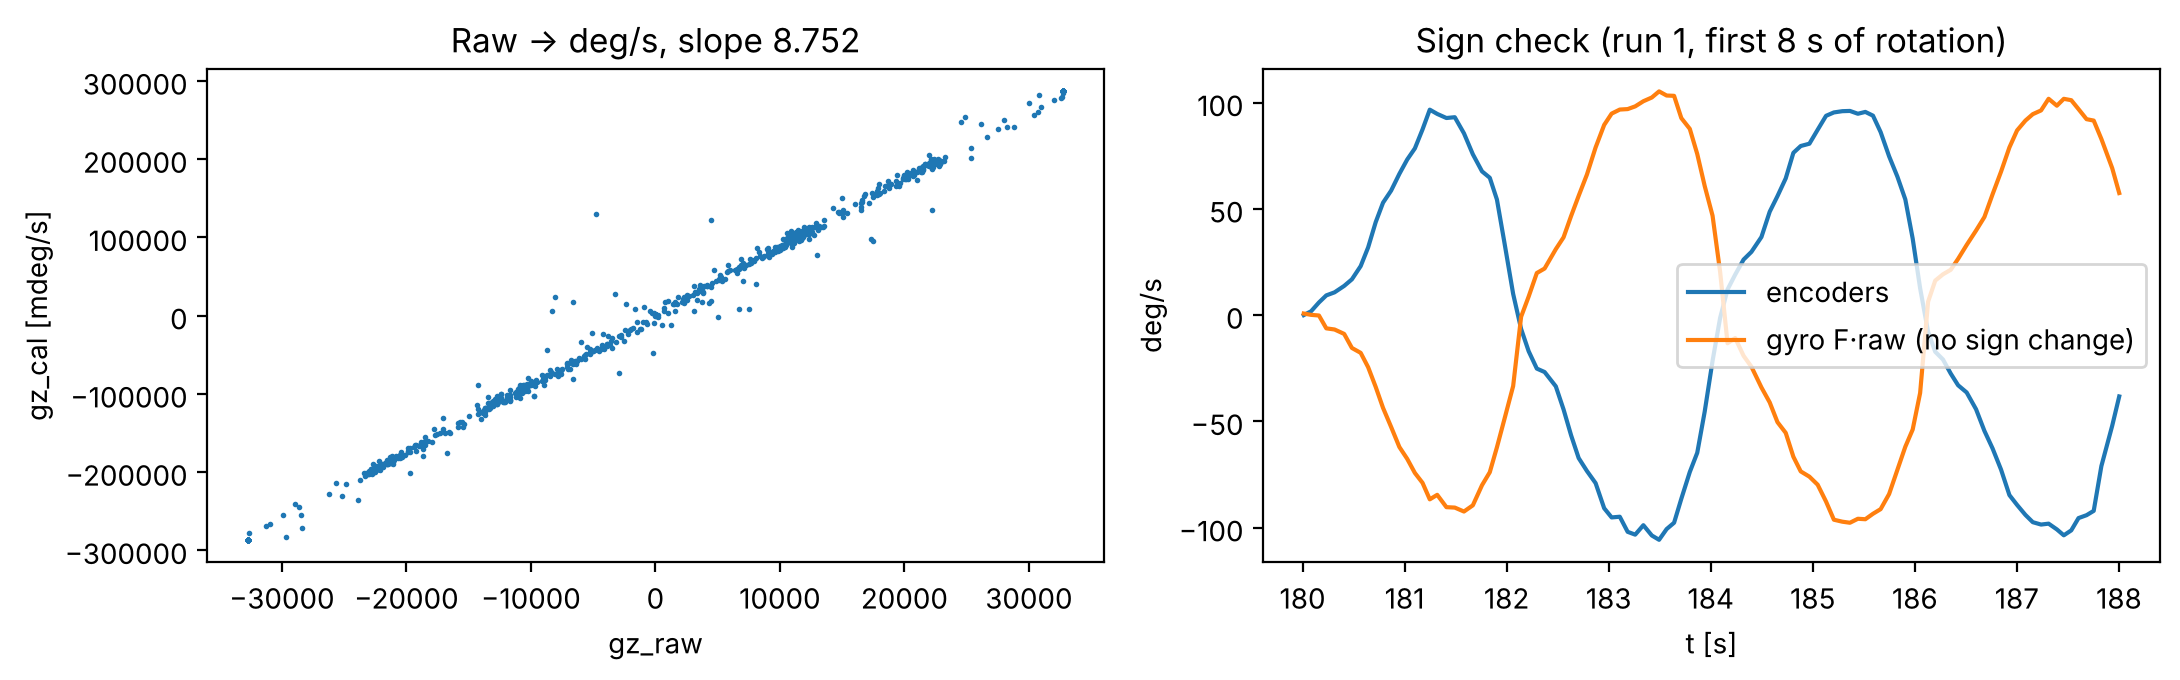

In [3]:
for k, R in runs.items():
    m = R['rot'] & ~R['clip']
    p = np.polyfit(R['raw'][m], R['cal'][m], 1)
    res = np.abs(R['cal'] - np.polyval(p, R['raw']))
    m &= res < 5 * 1.4826 * np.median(res[m]) + 10                       # drop pairs from two different gyro samples
    R['F'] = np.polyfit(R['raw'][m], R['cal'][m], 1)[0] / 1000             # [deg/s per raw unit]
    R['sign'] = np.sign(np.corrcoef(R['raw'][R['rot']], R['w_enc'][R['rot']])[0, 1])
    R['w'] = R['sign'] * R['F'] * R['raw']
    print(f"{k}: F = {1000 * R['F']:.3f} mdeg/s per unit (datasheet L3GD20 at ±250 dps: 8.75); "
          f"raw > 0 when the robot turns {'CCW' if R['sign'] > 0 else 'CW'}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(R1['raw'][R1['rot']], R1['cal'][R1['rot']], '.', ms=2)
ax[0].set(xlabel='gz_raw', ylabel='gz_cal [mdeg/s]', title=f"Raw → deg/s, slope {1000 * R1['F']:.3f}")
s8 = R1['ph'] == 'sin'; s8 &= R1['t'] < R1['t'][s8][0] + 8
ax[1].plot(R1['t'][s8], R1['w_enc'][s8], label='encoders')
ax[1].plot(R1['t'][s8], R1['F'] * R1['raw'][s8], label='gyro F·raw (no sign change)')
ax[1].set(xlabel='t [s]', ylabel='deg/s', title='Sign check (run 1, first 8 s of rotation)'); ax[1].legend()
plt.tight_layout(); plt.show()

## 1. Offset $b_0$ and `calibrate_gyro`

$b_0$ = mean of the first 30 s of the static log, ± standard error $\sigma/\sqrt N$. Then $b_0(T)$ for T = 1 … 30 s.

**My method `calibrate_gyro(R, T)`:** first T seconds of the static log → drop spikes more than 4 robust σ from the median (robust σ = 1.4826·MAD) → mean.
**T = 30 s:** to pin $b_0$ to ±0.005 deg/s (95 %), $N = (2\sigma/0.005)^2 \approx 800$ samples are needed; at ~73 ms per sample that is ~60 s, so the full 30 s of the window is used.

run 1: b0 = -0.5392 ± 0.0035 deg/s, calibrate_gyro = -0.5392 deg/s;  heading after 3 min still: -100.2 deg uncorrected, -3.11 deg after calibrate_gyro
run 2: b0 = -0.6528 ± 0.0034 deg/s, calibrate_gyro = -0.6528 deg/s;  heading after 3 min still: -112.4 deg uncorrected, 5.12 deg after calibrate_gyro


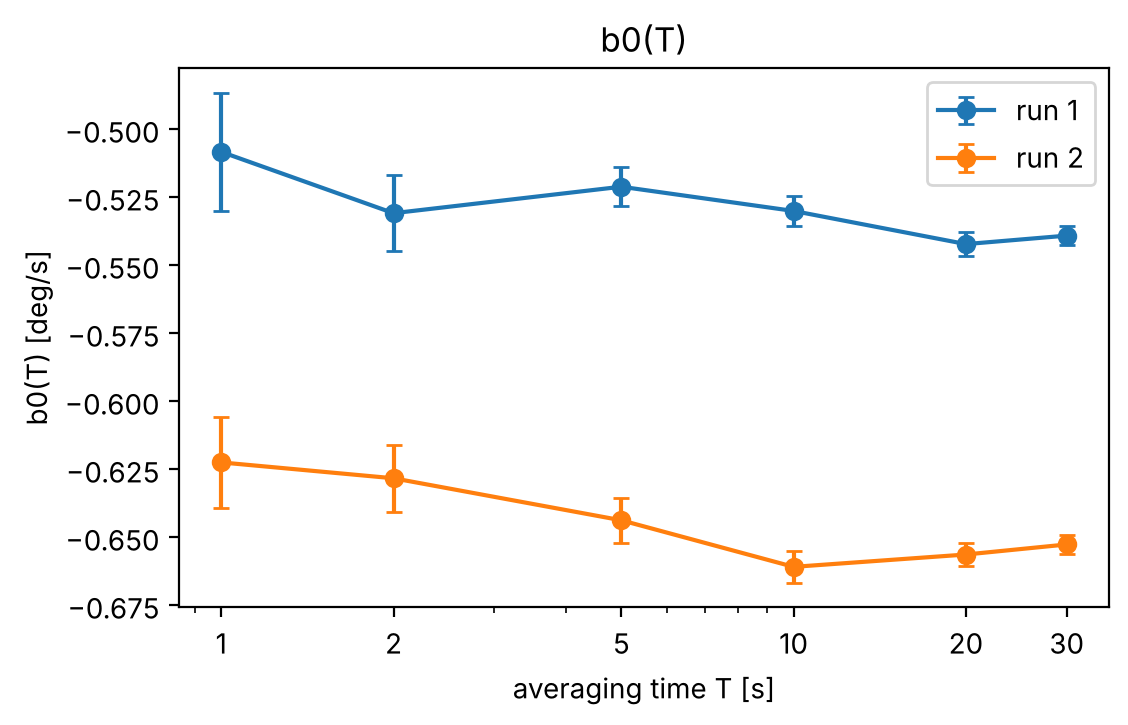

In [4]:
def calibrate_gyro(R, T=30):
    w = R['w'][R['st']][R['tg'][R['st']] - R['tg'][R['st']][0] < T]
    med = np.median(w)
    return w[np.abs(w - med) <= 4 * 1.4826 * np.median(np.abs(w - med))].mean()

T_list = [1, 2, 5, 10, 20, 30]
plt.figure(figsize=(6, 3.5))
for k, R in runs.items():
    R['ts'] = R['tg'][R['st']] - R['tg'][R['st']][0]; R['ws'] = R['w'][R['st']]   # static log: time, rate
    b = [R['ws'][R['ts'] < T].mean() for T in T_list]
    e = [R['ws'][R['ts'] < T].std() / np.sqrt(np.sum(R['ts'] < T)) for T in T_list]
    plt.errorbar(T_list, b, yerr=e, fmt='o-', capsize=3, label=k)
    R['b0'], R['se'], R['bcal'] = b[-1], e[-1], calibrate_gyro(R)
    R['th_raw'] = cumtrapz(R['ws'], R['ts'], initial=0)
    R['th_cal'] = cumtrapz(R['ws'] - R['bcal'], R['ts'], initial=0)
    print(f"{k}: b0 = {R['b0']:.4f} ± {R['se']:.4f} deg/s, calibrate_gyro = {R['bcal']:.4f} deg/s;  heading after 3 min still: "
          f"{R['th_raw'][-1]:.1f} deg uncorrected, {R['th_cal'][-1]:.2f} deg after calibrate_gyro")
plt.xscale('log'); plt.xticks(T_list, T_list); plt.xlabel('averaging time T [s]'); plt.ylabel('b0(T) [deg/s]')
plt.title('b0(T)'); plt.legend(); plt.show()

## 2. Bias drift $d$

3-min static log in 30-s windows, line through the window means → $d$. Heading: (a) raw rate, drift dominated by $b_0$; (b) rate − $b_0$, residual drift.

run 1: d = -0.0072 deg/s/min; (a) uncorrected -33.5 deg/min (b0·60 = -32.4); (b) after b0 removed: -0.58 / -1.86 / -3.11 deg at 1/2/3 min
run 2: d = +0.0106 deg/s/min; (a) uncorrected -37.3 deg/min (b0·60 = -39.2); (b) after b0 removed: +0.89 / +2.87 / +5.12 deg at 1/2/3 min


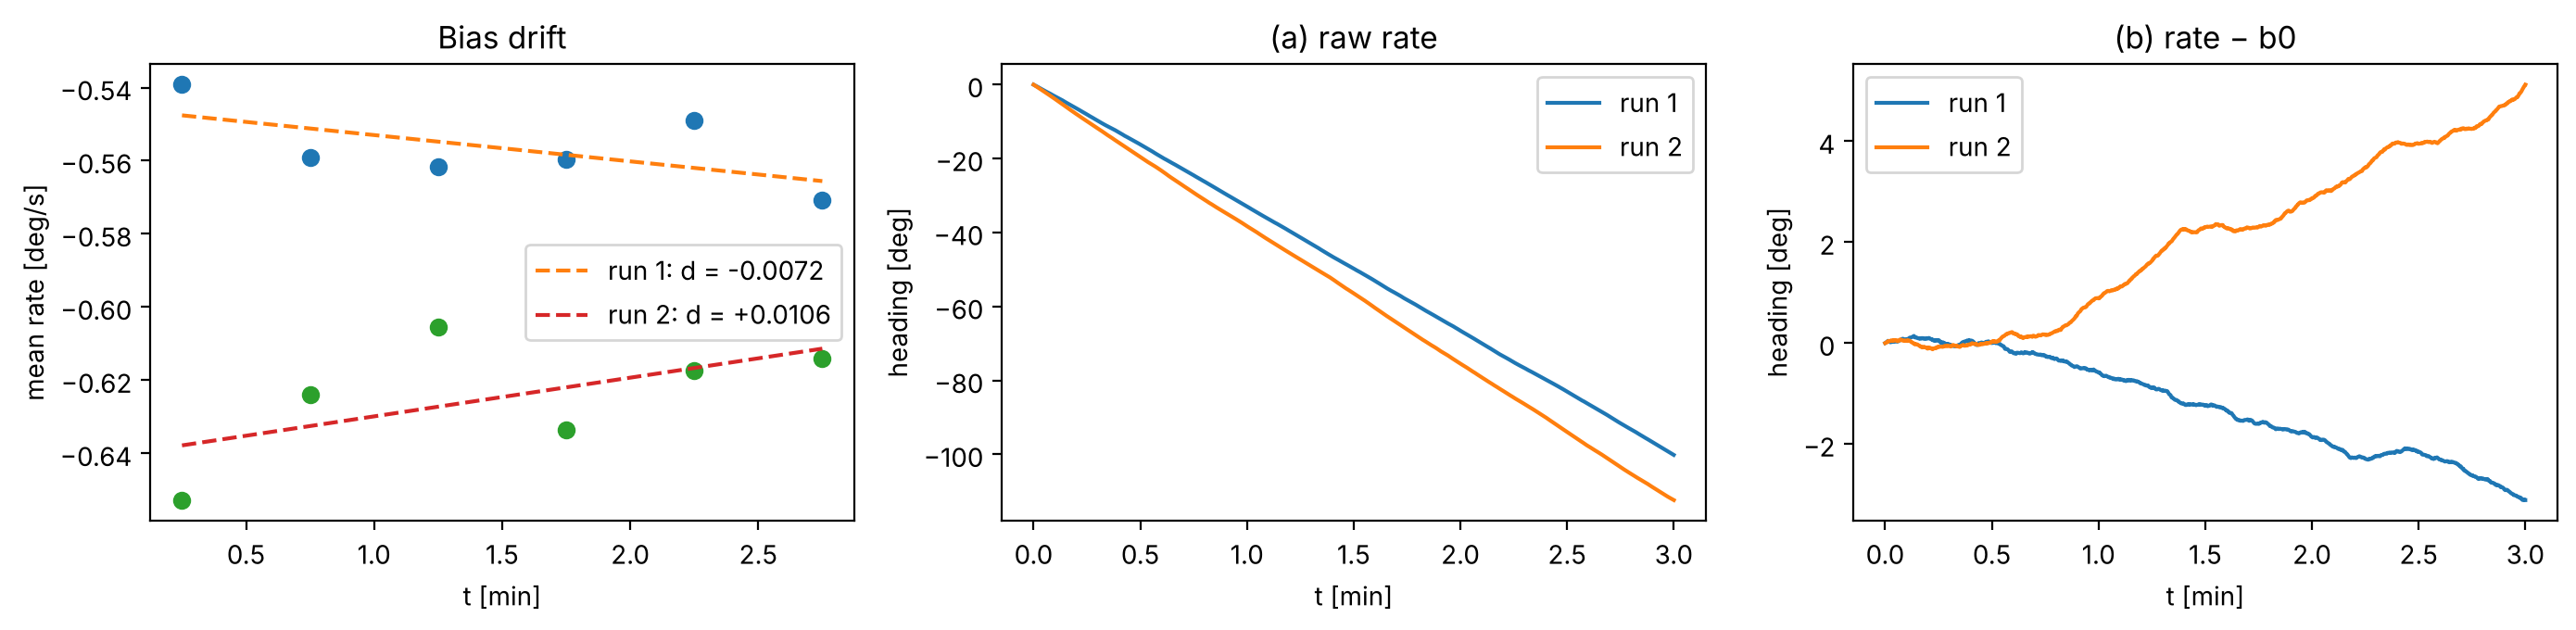

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for k, R in runs.items():
    c = np.arange(15, 180, 30)
    means = [R['ws'][(R['ts'] >= x - 15) & (R['ts'] < x + 15)].mean() for x in c]
    R['d'], b_line = np.polyfit(c / 60, means, 1)                      # [deg/s per min]
    R['b_line'] = b_line
    R['slope_a'] = np.polyfit(R['ts'] / 60, R['th_raw'], 1)[0]         # [deg/min]
    th_b = cumtrapz(R['ws'] - R['b0'], R['ts'], initial=0)
    ax[0].plot(c / 60, means, 'o'); ax[0].plot(c / 60, R['d'] * c / 60 + b_line, '--', label=f"{k}: d = {R['d']:+.4f}")
    ax[1].plot(R['ts'] / 60, R['th_raw'], label=k); ax[2].plot(R['ts'] / 60, th_b, label=k)
    print(f"{k}: d = {R['d']:+.4f} deg/s/min; (a) uncorrected {R['slope_a']:.1f} deg/min (b0·60 = {60 * R['b0']:.1f}); "
          f"(b) after b0 removed: {np.interp(60, R['ts'], th_b):+.2f} / {np.interp(120, R['ts'], th_b):+.2f} / {th_b[-1]:+.2f} deg at 1/2/3 min")
ax[0].set(xlabel='t [min]', ylabel='mean rate [deg/s]', title='Bias drift'); ax[0].legend()
ax[1].set(xlabel='t [min]', ylabel='heading [deg]', title='(a) raw rate'); ax[1].legend()
ax[2].set(xlabel='t [min]', ylabel='heading [deg]', title='(b) rate − b0'); ax[2].legend()
plt.tight_layout(); plt.show()

## 3. Range $\omega_{max}$

At A = 150 % the robot turns at full power. Where the gyro output stays flat while the encoders go higher, the gyro is saturated.

run 1: ω_max = -286.7 / +286.5 deg/s (226 clipped samples, raw -32736 / 32764); encoders up to 395 deg/s
run 2: ω_max = -287.6 / +287.3 deg/s (258 clipped samples, raw -32736 / 32764); encoders up to 399 deg/s


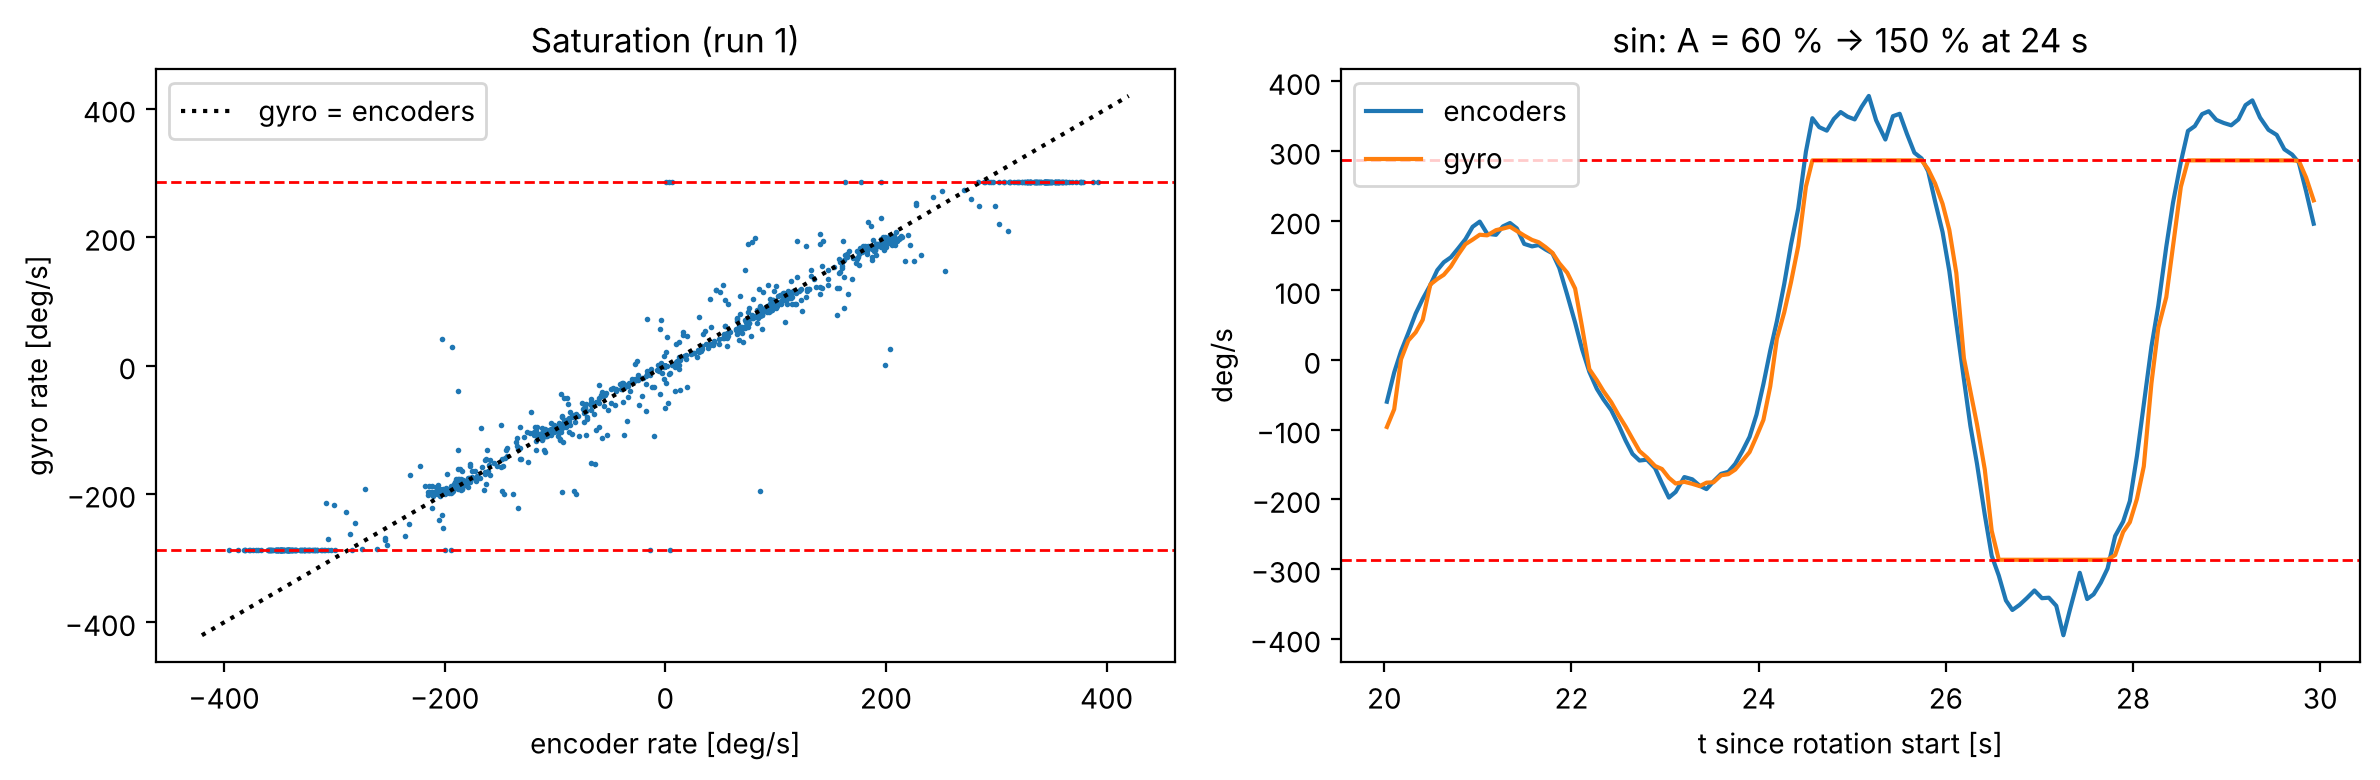

In [6]:
for k, R in runs.items():
    wc = R['w'][R['clip']]
    R['wmax'] = (wc.min(), wc.max())
    print(f"{k}: ω_max = {wc.min():.1f} / +{wc.max():.1f} deg/s ({R['clip'].sum()} clipped samples, raw {R['raw'][R['rot']].min():.0f} / "
          f"{R['raw'][R['rot']].max():.0f}); encoders up to {np.abs(R['w_enc'][R['rot']]).max():.0f} deg/s")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rot = R1['rot']
ax[0].plot(R1['w_enc'][rot], R1['w'][rot], '.', ms=2); lim = 420
ax[0].plot([-lim, lim], [-lim, lim], 'k:', label='gyro = encoders')
for v in R1['wmax']: ax[0].axhline(v, color='r', ls='--', lw=1)
ax[0].set(xlabel='encoder rate [deg/s]', ylabel='gyro rate [deg/s]', title='Saturation (run 1)'); ax[0].legend()
t0 = R1['t'][rot][0]; z = rot & (R1['t'] > t0 + 20) & (R1['t'] < t0 + 30)
ax[1].plot(R1['t'][z] - t0, R1['w_enc'][z], label='encoders'); ax[1].plot(R1['t'][z] - t0, R1['w'][z], label='gyro')
for v in R1['wmax']: ax[1].axhline(v, color='r', ls='--', lw=1)
ax[1].set(xlabel='t since rotation start [s]', ylabel='deg/s', title='sin: A = 60 % → 150 % at 24 s'); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Resolution $\Delta$ and 5. Noise $\sigma$

$\Delta$ = smallest step between distinct raw values while still × F. $\sigma$ = std of the static log minus $b_0$ (measurement noise **R** for Lab 12).

run 1: Δ = 0.00875 deg/s, σ = 0.0709 deg/s; within 1/2/3σ: 65.9 / 94.9 / 99.7 % (Gaussian 68.3 / 95.4 / 99.7)
run 2: Δ = 0.00878 deg/s, σ = 0.0736 deg/s; within 1/2/3σ: 66.8 / 94.2 / 99.5 % (Gaussian 68.3 / 95.4 / 99.7)


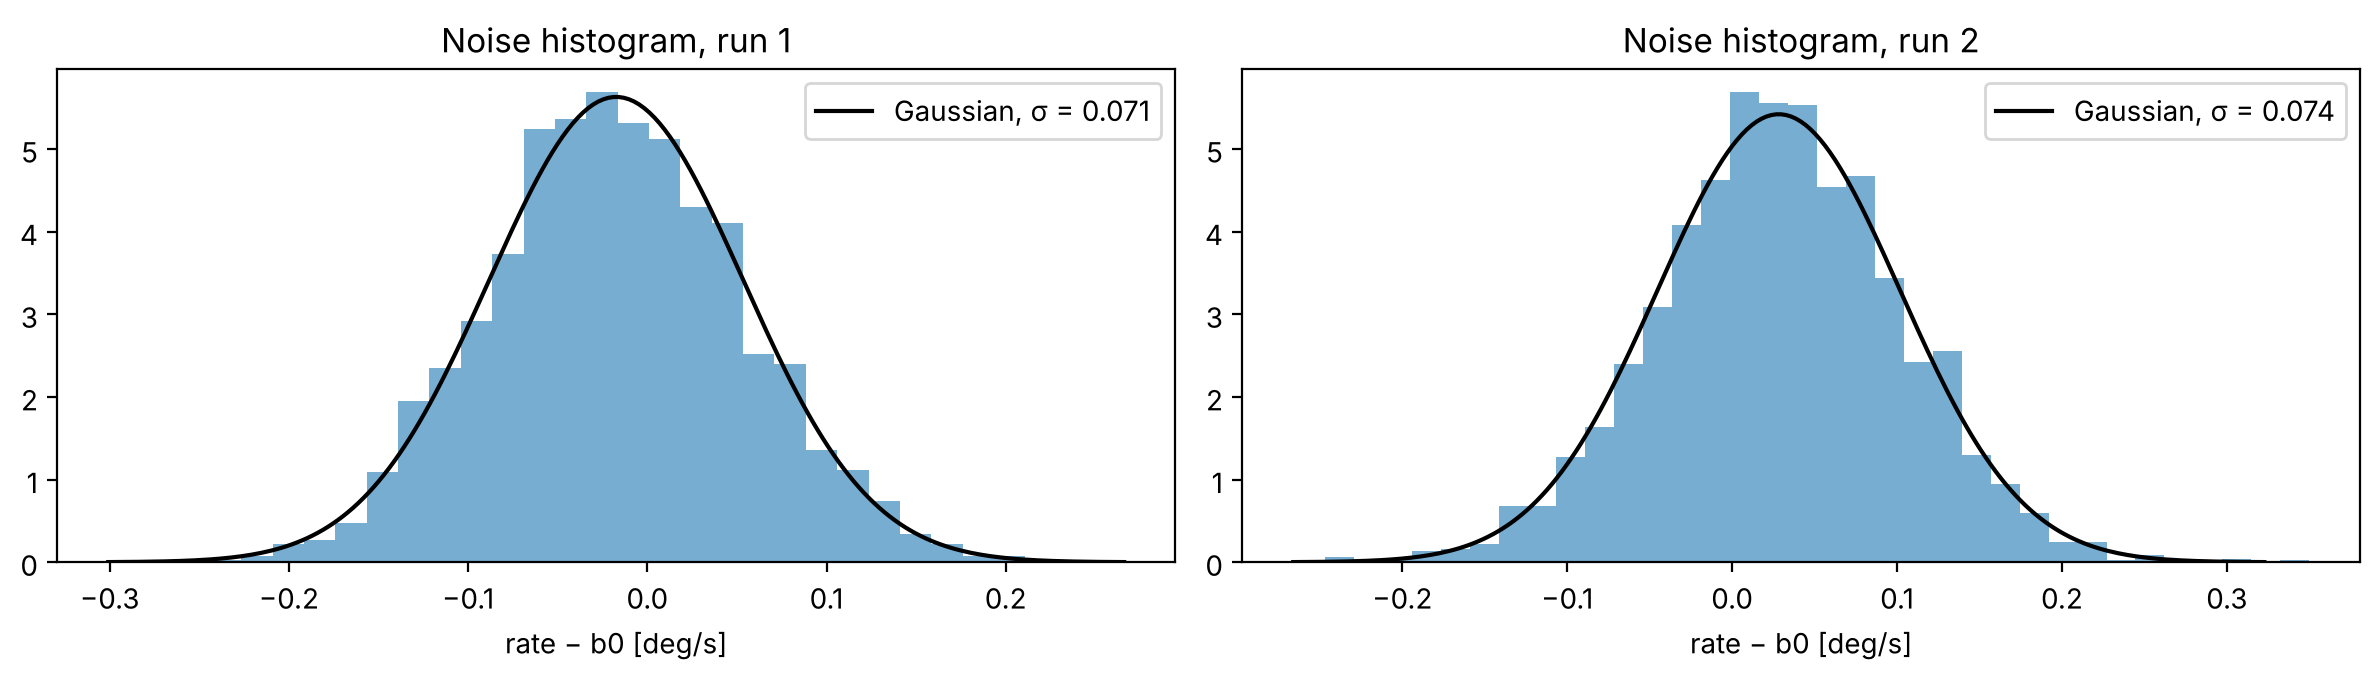

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for (k, R), ax in zip(runs.items(), axs):
    R['delta'] = np.diff(np.unique(R['raw'][R['st']])).min() * R['F']
    n = R['ws'] - R['b0']; R['sigma'] = n.std()
    within = [100 * np.mean(np.abs(n) < j * R['sigma']) for j in (1, 2, 3)]
    print(f"{k}: Δ = {R['delta']:.5f} deg/s, σ = {R['sigma']:.4f} deg/s; within 1/2/3σ: "
          f"{within[0]:.1f} / {within[1]:.1f} / {within[2]:.1f} % (Gaussian 68.3 / 95.4 / 99.7)")
    k_ = np.round(R['ws'] / R['delta'])                          # raw steps; one bin = 2 steps
    ax.hist(n, bins=(np.arange(k_.min() - 1, k_.max() + 3, 2) - 0.5) * R['delta'] - R['b0'], density=True, alpha=0.6)
    x = np.linspace(-4 * R['sigma'], 4 * R['sigma'], 200) + n.mean()
    ax.plot(x, stats.norm.pdf(x, n.mean(), R['sigma']), 'k', label=f"Gaussian, σ = {R['sigma']:.3f}")
    ax.set(xlabel='rate − b0 [deg/s]', title=f'Noise histogram, {k}'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Scale factor $s$

$\theta_{gyro} = \int(\omega - b_0)\,dt$ (with `calibrate_gyro`), $\theta_{enc}$ from the wheels. The rotation is cut into single turns, from one stop (or reversal) to the next, using the encoder rate.
For each turn $\Delta\theta_{gyro}$ is compared with $\Delta\theta_{enc}$; the slope through the origin is $1+s$, CCW and CW separately. Turns where the gyro clipped are left out (they belong to §3).

run 1: s_CCW = -3.31 %, s_CW = -4.48 % (24 unsaturated of 35 turns)
run 2: s_CCW = -2.87 %, s_CW = -3.52 % (24 unsaturated of 35 turns)

run 1, s per part [%]:


dir,CCW,CW
part,,
sin 30,-2.25,-2.07
sin 60,-2.45,-3.02
rect 30,-2.17,-2.94
rect 60,-4.24,-6.02


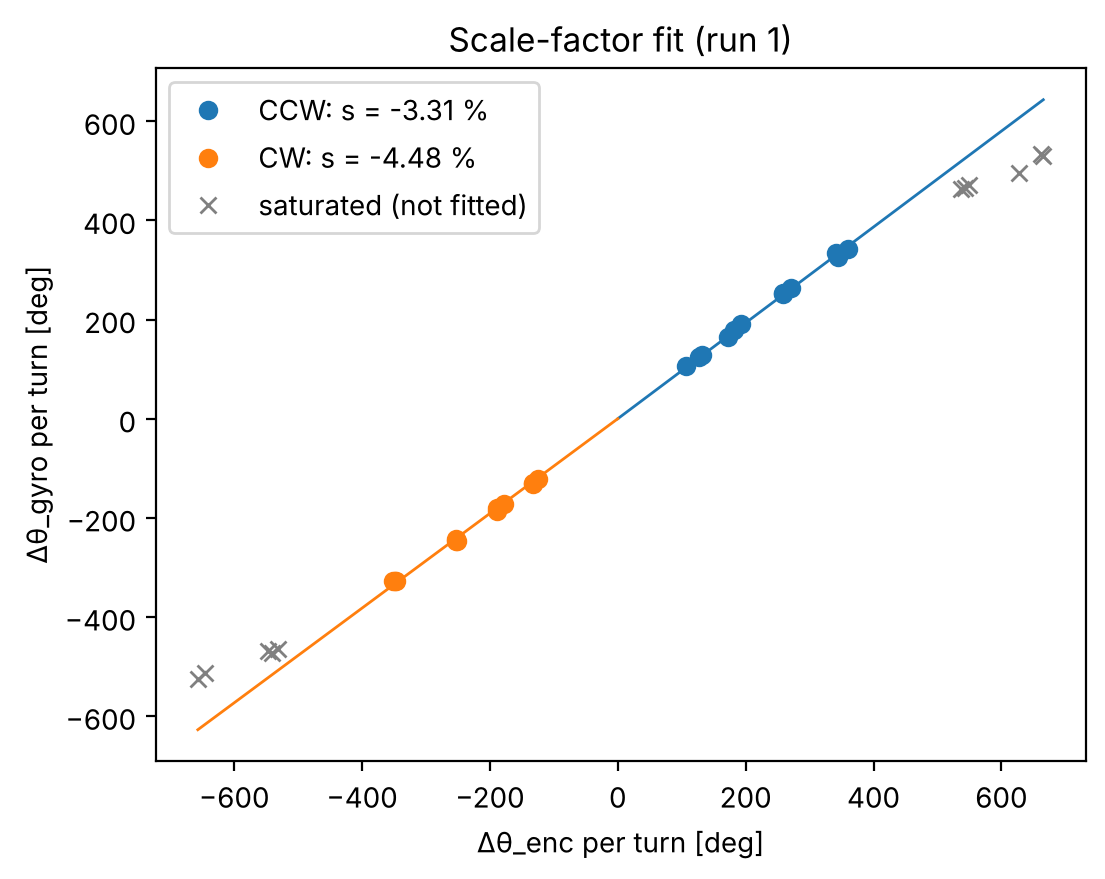

In [8]:
def turns(R):
    i0 = np.where(R['rot'])[0][0]
    tg = cumtrapz(R['w'][R['rot']] - R['bcal'], R['tg'][R['rot']], initial=0)    # θ_gyro from rotation start
    te = R['th'][R['rot']] - R['th'][i0]                                        # θ_enc from rotation start
    d = np.where(R['w_enc'][R['rot']] > 5, 1, np.where(R['w_enc'][R['rot']] < -5, -1, 0))
    moving = np.flatnonzero(d)
    starts = np.r_[moving[0], moving[1:][np.diff(d[moving]) != 0]]              # first sample of each turn
    ends = np.r_[starts[1:] - 1, moving[-1]]
    cuts = np.r_[0, (ends[:-1] + starts[1:]) // 2, len(d) - 1]                  # cut in the middle of the still gap
    ph, tt, cl = R['ph'][R['rot']], R['t'][R['rot']], R['clip'][R['rot']]
    out = []
    for a, b, s in zip(cuts[:-1], cuts[1:], starts):
        mid = (a + b) // 2
        if ph[mid] == 'rest': continue
        A = [30, 60, 150][min(int((tt[mid] - tt[ph == ph[mid]][0]) // 12), 2)]
        out.append(dict(dir='CCW' if d[s] > 0 else 'CW', part=f'{ph[mid]} {A}', d_enc=te[b] - te[a], d_gyro=tg[b] - tg[a], sat=cl[a:b + 1].any()))
    return pd.DataFrame(out), tg, te

fit = lambda g: (g.d_gyro * g.d_enc).sum() / (g.d_enc ** 2).sum() - 1       # slope through origin minus 1
for k, R in runs.items():
    R['turns'], R['th_g'], R['th_e'] = turns(R)
    ok = R['turns'][~R['turns'].sat]
    R['s'] = {D: fit(ok[ok.dir == D]) for D in ('CCW', 'CW')}
    print(f"{k}: s_CCW = {100 * R['s']['CCW']:+.2f} %, s_CW = {100 * R['s']['CW']:+.2f} % ({len(ok)} unsaturated of {len(R['turns'])} turns)")
ok = R1['turns'][~R1['turns'].sat]
print('\nrun 1, s per part [%]:'); display((100 * ok.groupby(['part', 'dir'], sort=False).apply(fit, include_groups=False)).unstack().round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
for D, c in (('CCW', 'C0'), ('CW', 'C1')):
    g = R1['turns'][R1['turns'].dir == D]
    ax.plot(g.d_enc[~g.sat], g.d_gyro[~g.sat], 'o', color=c, label=f"{D}: s = {100 * R1['s'][D]:+.2f} %")
    ax.plot(g.d_enc[g.sat], g.d_gyro[g.sat], 'x', color='grey')
    x = np.array([0, g.d_enc.abs().max() * np.sign(g.d_enc.iloc[0])]); ax.plot(x, (1 + R1['s'][D]) * x, color=c, lw=1)
ax.plot([], [], 'x', color='grey', label='saturated (not fitted)')
ax.set(xlabel='Δθ_enc per turn [deg]', ylabel='Δθ_gyro per turn [deg]', title='Scale-factor fit (run 1)'); ax.legend(); plt.show()

## Gyro against encoders over the rotation run (Step 3)

$e(t) = \theta_{gyro} - \theta_{enc}$. The table shows how much $e$ changes in each part of the run.

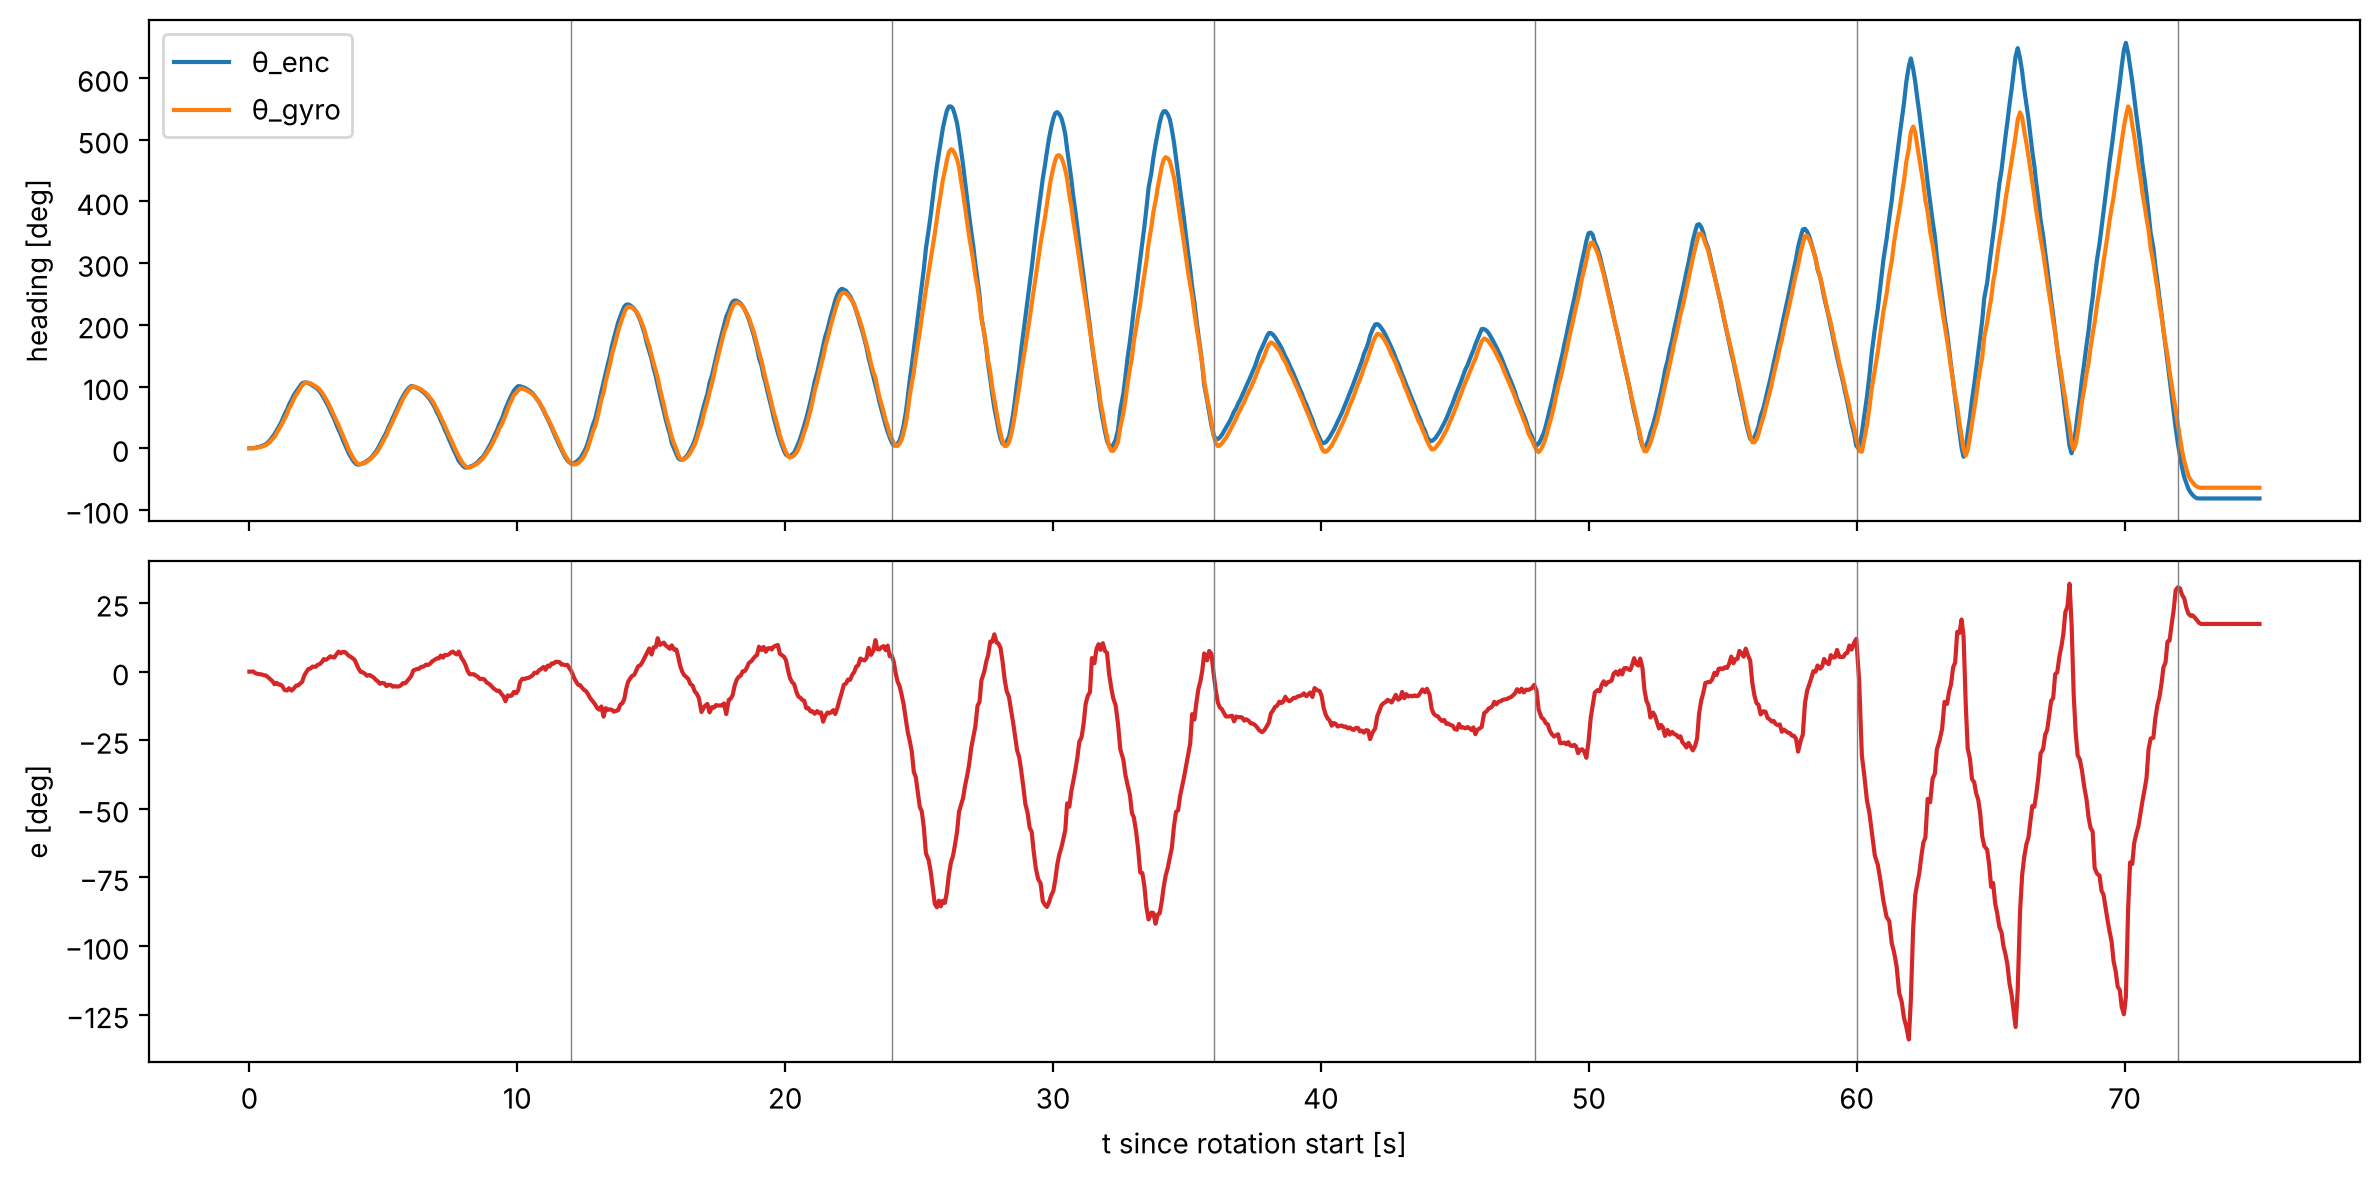

          change of e [deg]  clipped samples
sin 30                  1.4              0.0
sin 60                  5.7              0.0
sin 150                 2.7             92.0
rect 30                -4.2              0.0
rect 60                18.8              0.0
rect 150               32.9            133.0
rest                  -13.4              1.0


In [9]:
rot = R1['rot']; tt = R1['t'][rot] - R1['t'][rot][0]; e = R1['th_g'] - R1['th_e']
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(tt, R1['th_e'], label='θ_enc'); ax[0].plot(tt, R1['th_g'], label='θ_gyro'); ax[0].set(ylabel='heading [deg]'); ax[0].legend()
ax[1].plot(tt, e, 'C3'); ax[1].set(xlabel='t since rotation start [s]', ylabel='e [deg]')
for x in range(12, 84, 12):
    for a in ax: a.axvline(x, color='grey', lw=0.5)
plt.tight_layout(); plt.show()

ph = R1['ph'][rot]; start = {p: tt[ph == p][0] for p in ('sin', 'rect')}
part = np.array(['rest' if p == 'rest' else f"{p} {[30, 60, 150][min(int((x - start[p]) // 12), 2)]}" for p, x in zip(ph, tt)])
print(pd.DataFrame({p: {'change of e [deg]': round(e[part == p][-1] - e[part == p][0], 1),
                        'clipped samples': int(R1['clip'][rot][part == p].sum())} for p in dict.fromkeys(part)}).T)

## Simulated gyro `gyro_sim(omega_true, t)`

The model with the parameters of run 1 ($s$ per direction, $t$ = time since the static log started). Test: the encoder rate of the recorded rotation goes in, the output is drawn over the real gyro.

heading RMS difference from the real gyro: gyro_sim 29.8 deg, ideal gyro (= encoders) 34.7 deg


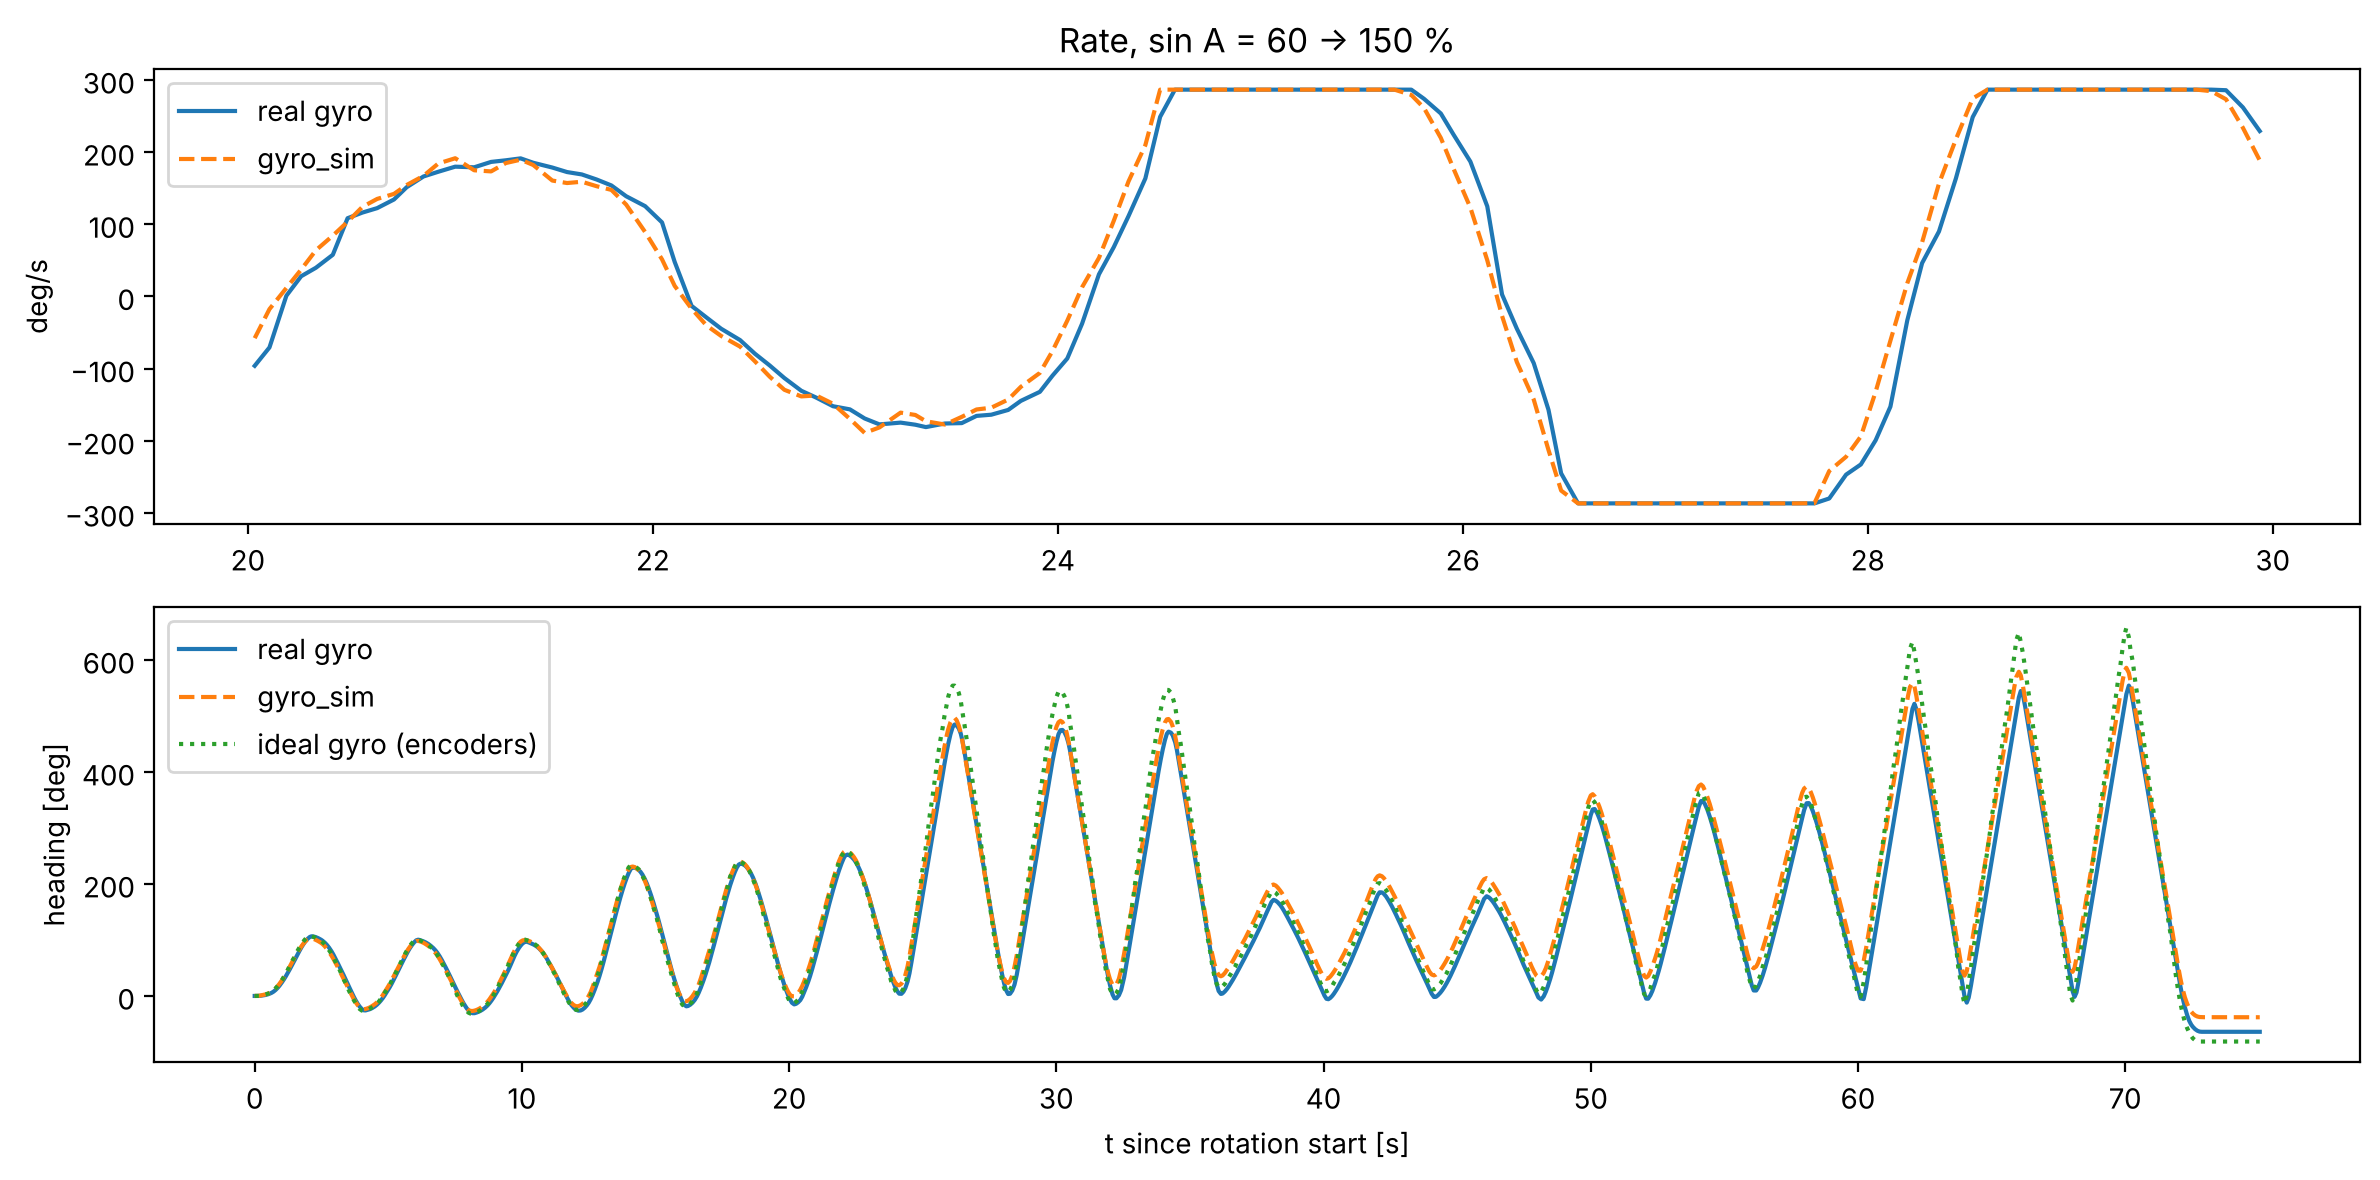

In [10]:
P = dict(b0=R1['b0'], d=R1['d'], sigma=R1['sigma'], delta=R1['delta'], wmax=R1['wmax'], s_ccw=R1['s']['CCW'], s_cw=R1['s']['CW'])

def gyro_sim(omega_true, t, p=P, seed=0):
    s = np.where(omega_true >= 0, p['s_ccw'], p['s_cw'])
    w = (1 + s) * omega_true + p['b0'] + p['d'] * t / 60 + np.random.default_rng(seed).normal(0, p['sigma'], len(t))
    w = np.clip(w, *p['wmax'])                                  # saturation
    return p['delta'] * np.round(w / p['delta'])                # quantisation

rot = R1['rot']; tg = R1['tg'][rot]; tt = tg - tg[0]
w_sim = gyro_sim(R1['w_enc'][rot], tg)
th_sim = cumtrapz(w_sim - R1['bcal'], tg, initial=0)
rms = lambda x: np.sqrt(np.mean(x ** 2))
print(f"heading RMS difference from the real gyro: gyro_sim {rms(th_sim - R1['th_g']):.1f} deg, ideal gyro (= encoders) {rms(R1['th_e'] - R1['th_g']):.1f} deg")
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
z = (tt > 20) & (tt < 30)
ax[0].plot(tt[z], R1['w'][rot][z], label='real gyro'); ax[0].plot(tt[z], w_sim[z], '--', label='gyro_sim')
ax[0].set(ylabel='deg/s', title='Rate, sin A = 60 → 150 %'); ax[0].legend()
ax[1].plot(tt, R1['th_g'], label='real gyro'); ax[1].plot(tt, th_sim, '--', label='gyro_sim'); ax[1].plot(tt, R1['th_e'], ':', label='ideal gyro (encoders)')
ax[1].set(xlabel='t since rotation start [s]', ylabel='heading [deg]'); ax[1].legend()
plt.tight_layout(); plt.show()

## Parameter table

In [11]:
row = lambda f: [f(R) for R in runs.values()]
table = pd.DataFrame([
    ['Offset (bias)', 'b0', *row(lambda R: f"{R['b0']:.3f} ± {R['se']:.3f}"), 'deg/s', 'static mean, T = 30 s'],
    ['Bias drift', 'd', *row(lambda R: f"{R['d']:+.4f}"), 'deg/s/min', '30-s window means'],
    ['Heading drift, uncorrected', '', *row(lambda R: f"{R['slope_a']:.1f}"), 'deg/min', 'slope of θ(t)'],
    ['Measurement range', '±ω_max', *row(lambda R: f"{R['wmax'][0]:.1f} / +{R['wmax'][1]:.1f}"), 'deg/s', 'saturation at A = 150 %'],
    ['Resolution', 'Δ', *row(lambda R: f"{R['delta']:.5f}"), 'deg/s', '1 raw unit × F'],
    ['Noise std', 'σ', *row(lambda R: f"{R['sigma']:.4f}"), 'deg/s', 'static, 3 min'],
    ['Raw → deg/s factor', 'F', *row(lambda R: f"{R['F']:.6f}"), 'deg/s per raw unit', 'read()[2] vs readRawData()[2]'],
    ['Scale-factor error CCW / CW', 's', *row(lambda R: f"{100 * R['s']['CCW']:+.2f} / {100 * R['s']['CW']:+.2f}"), '%', 'gyro vs encoder angle, unsaturated turns'],
    ['Positive rotation direction', '', *row(lambda R: 'CCW' if R['sign'] > 0 else 'CW'), '—', 'gyro vs encoder sign'],
], columns=['Parameter', 'Symbol', *runs, 'Unit', 'Method'])
table

,Parameter,Symbol,run 1,run 2,Unit,Method
0,Offset (bias),b0,-0.539 ± 0.004,-0.653 ± 0.003,deg/s,"static mean, T = 30 s"
1,Bias drift,d,-0.0072,+0.0106,deg/s/min,30-s window means
2,"Heading drift, uncorrected",,-33.5,-37.3,deg/min,slope of θ(t)
3,Measurement range,±ω_max,-286.7 / +286.5,-287.6 / +287.3,deg/s,saturation at A = 150 %
4,Resolution,Δ,0.00875,0.00878,deg/s,1 raw unit × F
5,Noise std,σ,0.0709,0.0736,deg/s,"static, 3 min"
6,Raw → deg/s factor,F,0.008752,0.008778,deg/s per raw unit,read()[2] vs readRawData()[2]
7,Scale-factor error CCW / CW,s,-3.31 / -4.48,-2.87 / -3.52,%,"gyro vs encoder angle, unsaturated turns"
8,Positive rotation direction,,CW,CW,—,gyro vs encoder sign


## For the analysis: heading error budget (run 1)

Offset not removed: $b_0 t$. Offset left after `calibrate_gyro`: $|b_{line}(0) - b_{cal}|\,t$. Drift: $\tfrac12 \frac{d}{60} t^2$. Noise (random walk): $\sigma\sqrt{t\,T_s}$. Measured: static log integrated after `calibrate_gyro`.

In [12]:
Ts = np.median(np.diff(R1['ts']))
budget = pd.DataFrame({f'{lab} [deg]': {'offset b0, not removed': abs(R1['b0']) * x,
                                        'offset left after calibrate_gyro': abs(R1['b_line'] - R1['bcal']) * x,
                                        'drift d': 0.5 * abs(R1['d']) / 60 * x ** 2,
                                        'noise σ': R1['sigma'] * np.sqrt(x * Ts),
                                        'measured after calibrate_gyro': abs(np.interp(x, R1['ts'], R1['th_cal']))}
                       for lab, x in (('10 s', 10), ('1 min', 60), ('3 min', 180))}).round(2)
budget

,10 s [deg],1 min [deg],3 min [deg]
"offset b0, not removed",5.39,32.35,97.06
offset left after calibrate_gyro,0.07,0.40,1.19
drift d,0.01,0.22,1.94
noise σ,0.06,0.15,0.26
measured after calibrate_gyro,0.09,0.58,3.11


## Short analysis

**Which error dominates (run 1, table above).**
- **Without calibration:** the offset $b_0$ dominates at every time, and its error grows linearly: 5.4° after 10 s, 32° after 1 min, 97° after 3 min (−33.5 deg/min).
- **After `calibrate_gyro`:** what is left of the offset dominates up to 1 min (0.07° and 0.4°), and the drift $d$ takes over by 3 min (1.9°, it grows with $t^2$). Noise is the smallest term (0.26° after 3 min, it grows only with $\sqrt t$). Measured on the static log, 3.1° is left after 3 min instead of 100°.
- **While turning:** the scale factor costs $|s|\cdot360° \approx 16°$ per full turn ($s$ = −3.3 % CCW, −4.5 % CW), more than all the time-dependent errors after 1 min. Every turn faster than ±287 deg/s loses about 100° to saturation, the largest error of all. In $e(t)$ this shows as small swings in the 30/60 % parts (scale factor) and big jumps in the 150 % parts (saturation).
- **Wheel slip:** square-wave turns give a more negative $s$ than sine turns (rect 60: −4.2 / −6.0 %, sin 60: −2.5 / −3.0 %). The hard reversals make the wheels slip, so the encoders over-count the turn.

**Calibration.** `calibrate_gyro` averages the first 30 s of the static log after removing spikes. With one sample every ~73 ms, ±0.005 deg/s would need ~60 s of averaging, so the full 30 s is used: shorter is clearly worse, and longer would help only a little.

**Two runs.** F, Δ, σ, $\omega_{max}$, $s$ and the sign repeat, so they belong to the sensor. $b_0$ (−0.54 and −0.65 deg/s) and $d$ change after every power-on, so `calibrate_gyro` must run at every start.